# Acquisition readout: analysis notebook

Builds the dbt project (seeds, models and data tests) on the synthetic data, then draws the charts used in the README. Run `python data/generate.py` first.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from run_analysis import build, projection_accuracy, DB

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
IMG = Path('images'); IMG.mkdir(exist_ok=True)
COLORS = {'paid_search': '#2f6f8f', 'paid_social': '#d1495b', 'affiliate': '#e3a33b',
          'organic_search': '#6a994e', 'referral': '#8d6cab'}
LABELS = {'paid_search': 'Paid search', 'paid_social': 'Paid social', 'affiliate': 'Affiliate',
          'organic_search': 'Organic search', 'referral': 'Referral'}
build()
con = duckdb.connect(DB, read_only=True)

## 1. The funnel: a drop that is not there

Counting every start, the latest week always looks worse: some of those people started yesterday and have not had 7 days to finish. Counting only eligible starts, the drop disappears.

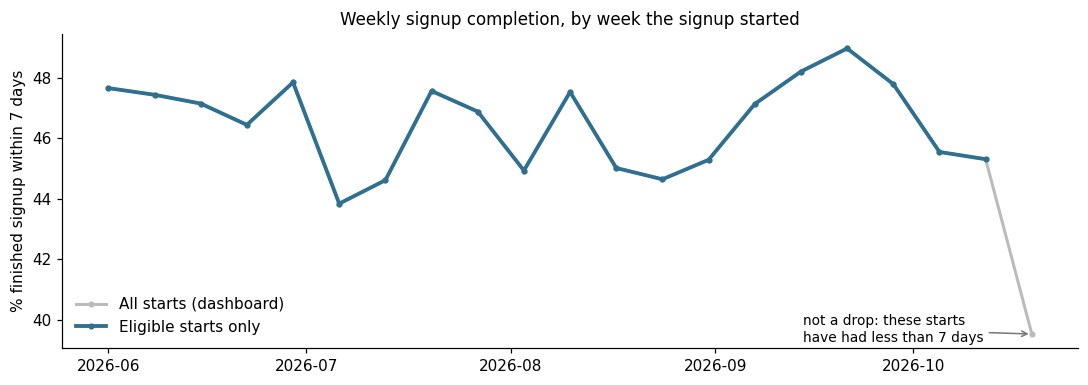

In [2]:
w = con.table('funnel_weekly').df()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(w.start_week, w.finished_7d_rate_naive * 100, color='#bbbbbb', lw=2, marker='o', ms=3, label='All starts (dashboard)')
ax.plot(w.start_week, w.finished_7d_rate * 100, color='#2f6f8f', lw=2.5, marker='o', ms=3, label='Eligible starts only')
last = w.iloc[-1]
ax.annotate('not a drop: these starts\nhave had less than 7 days', (last.start_week, last.finished_7d_rate_naive * 100),
            xytext=(-150, -5), textcoords='offset points', fontsize=9, arrowprops=dict(arrowstyle='->', color='#777'))
ax.set_ylabel('% finished signup within 7 days'); ax.legend(frameon=False, loc='lower left')
ax.set_title('Weekly signup completion, by week the signup started', fontsize=11)
fig.tight_layout(); fig.savefig(IMG / 'funnel_weekly.png', bbox_inches='tight')

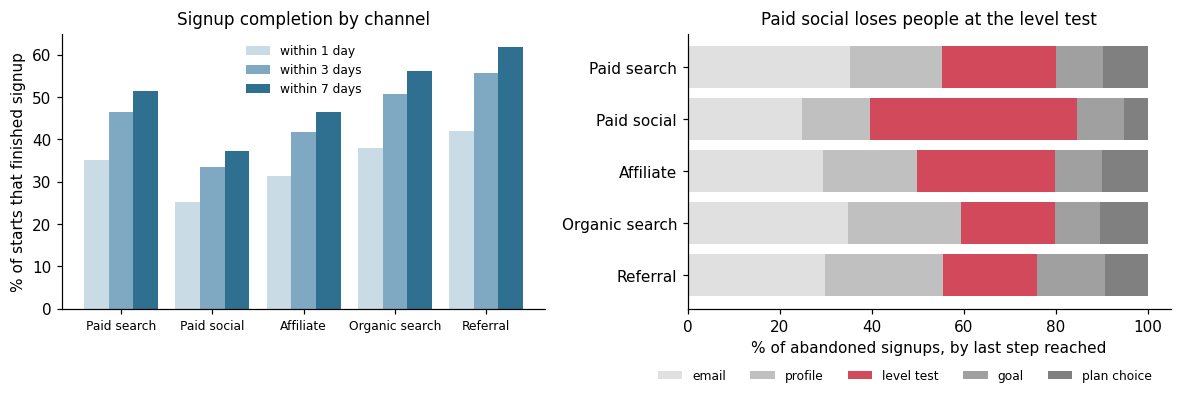

In [3]:
f = con.table('funnel_by_channel').df().set_index('channel').loc[list(LABELS)]
ls = con.table('funnel_last_step').df()
steps = ['email', 'profile', 'level_test', 'goal', 'plan_choice']
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
x = range(len(f))
for i, (n, shade) in enumerate([(1, '#c9dbe5'), (3, '#7fa9c2'), (7, '#2f6f8f')]):
    ax.bar([j + (i - 1) * 0.27 for j in x], f[f'finished_{n}d_rate'] * 100, 0.27, color=shade, label=f'within {n} day' + ('s' if n > 1 else ''))
ax.set_xticks(list(x)); ax.set_xticklabels([LABELS[c] for c in f.index], fontsize=8)
ax.set_ylabel('% of starts that finished signup'); ax.legend(frameon=False, fontsize=8)
ax.set_title('Signup completion by channel', fontsize=11)
ax = axes[1]
piv = ls.pivot(index='channel', columns='last_step_reached', values='share_of_abandoned').loc[list(LABELS), steps] * 100
left = pd.Series(0.0, index=piv.index)
shades = ['#e0e0e0', '#c0c0c0', '#d1495b', '#a0a0a0', '#808080']
for s, c in zip(steps, shades):
    ax.barh([LABELS[i] for i in piv.index], piv[s], left=left, color=c, label=s.replace('_', ' '))
    left += piv[s]
ax.invert_yaxis(); ax.set_xlabel('% of abandoned signups, by last step reached')
ax.legend(frameon=False, fontsize=8, ncol=5, loc='upper center', bbox_to_anchor=(0.45, -0.18))
ax.set_title('Paid social loses people at the level test', fontsize=11)
fig.tight_layout(); fig.savefig(IMG / 'funnel_by_channel.png', bbox_inches='tight')

## 2. Value curves: fast start, slow burn

Average cumulative value per member, only members old enough for each window.

window_name,14d,1m,3m,6m,12m,24m
channel,,,,,,
affiliate,1.29,1.29,4.65,11.23,30.76,69.17
organic_search,2.00,1.99,6.04,12.17,26.43,49.79
paid_search,2.58,2.59,7.43,14.20,27.87,47.56
paid_social,3.64,3.64,8.30,11.59,14.30,16.35
referral,2.85,2.85,8.50,16.74,34.80,63.93


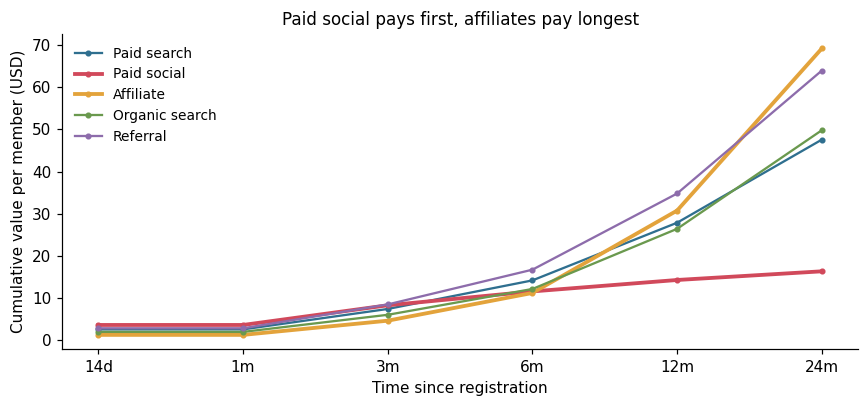

In [4]:
vc = con.table('value_curves').df()
order = ['14d', '1m', '3m', '6m', '12m', '24m']
fig, ax = plt.subplots(figsize=(8, 3.8))
for ch in LABELS:
    s = vc[vc.channel == ch].set_index('window_name').loc[order]
    ax.plot(order, s.avg_value_usd, color=COLORS[ch], lw=2.5 if ch in ('paid_social', 'affiliate') else 1.5, marker='o', ms=3, label=LABELS[ch])
ax.set_xlabel('Time since registration'); ax.set_ylabel('Cumulative value per member (USD)')
ax.legend(frameon=False, fontsize=9)
ax.set_title('Paid social pays first, affiliates pay longest', fontsize=11)
fig.tight_layout(); fig.savefig(IMG / 'value_curves.png', bbox_inches='tight')
vc.pivot(index='channel', columns='window_name', values='avg_value_usd')[order].round(2)

## 3. ROAS: the ranking flips

,members,spend_usd,spend_per_member,roas_14d,roas_so_far_naive,projected_roas_24m
channel,,,,,,
paid_social,3464.0,52850.07,15.257,0.237,0.737,1.144
paid_search,3400.0,56956.19,16.752,0.156,0.872,2.848
affiliate,1412.0,23427.90,16.592,0.075,0.751,4.195


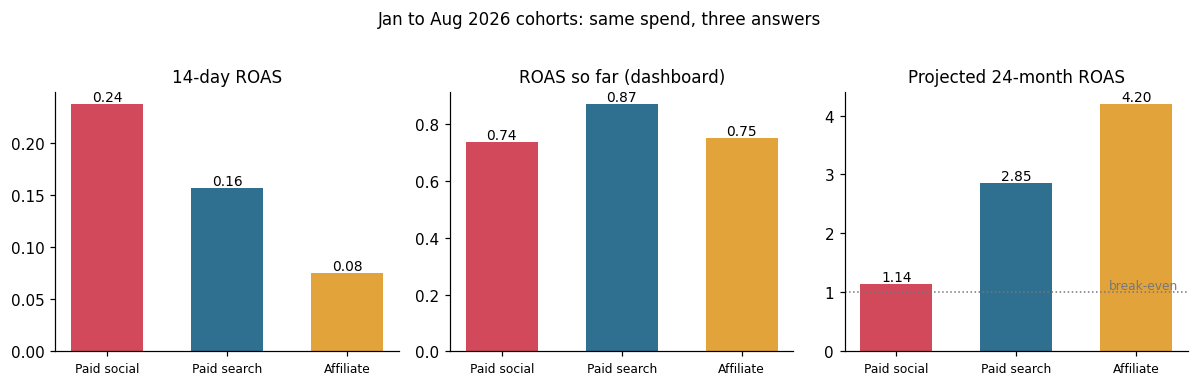

In [5]:
r = con.table('channel_roas_summary').df().set_index('channel').loc[['paid_social', 'paid_search', 'affiliate']]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=False)
for ax, col, title in zip(axes, ['roas_14d', 'roas_so_far_naive', 'projected_roas_24m'],
                          ['14-day ROAS', 'ROAS so far (dashboard)', 'Projected 24-month ROAS']):
    ax.bar([LABELS[c] for c in r.index], r[col], color=[COLORS[c] for c in r.index], width=0.6)
    for i, v in enumerate(r[col]):
        ax.text(i, v, f'{v:.2f}', ha='center', va='bottom', fontsize=9)
    ax.set_title(title, fontsize=11); ax.tick_params(axis='x', labelsize=8)
    if col == 'projected_roas_24m':
        ax.axhline(1, color='#777', ls=':', lw=1); ax.text(2.35, 1.05, 'break-even', fontsize=8, color='#777', ha='right')
fig.suptitle('Jan to Aug 2026 cohorts: same spend, three answers', fontsize=11, y=1.02)
fig.tight_layout(); fig.savefig(IMG / 'roas_rank_flip.png', bbox_inches='tight')
r.round(3)

## 4. Does the projection hold up?

Backtest: the same models as if today were 2024-10-31, projecting the Nov 2023 to Oct 2024 cohorts, compared with what those members really paid over 24 months.

,projected_value_24m,true_value_24m,error
channel,,,
paid_search,234612.113,240912.54,-0.026
paid_social,31125.619,32124.27,-0.031
affiliate,139202.748,147475.47,-0.056
organic_search,198296.730,214412.94,-0.075
referral,121447.571,121963.11,-0.004


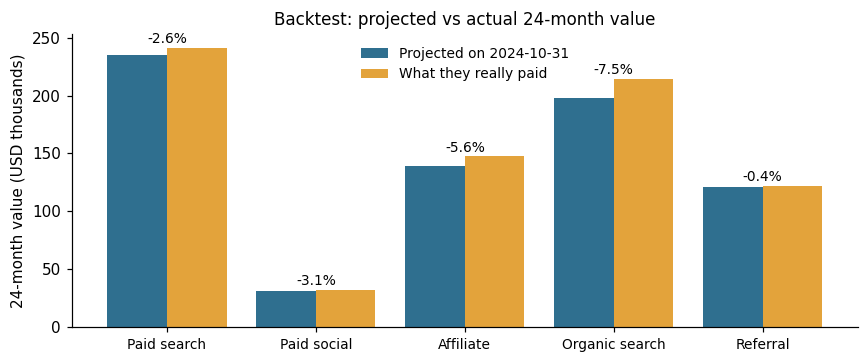

In [6]:
bt = projection_accuracy(con, 'backtest', '2023-11-01').set_index('channel').loc[list(LABELS)]
fig, ax = plt.subplots(figsize=(8, 3.4))
x = range(len(bt))
ax.bar([i - 0.2 for i in x], bt.projected_value_24m / 1000, 0.4, color='#2f6f8f', label='Projected on 2024-10-31')
ax.bar([i + 0.2 for i in x], bt.true_value_24m / 1000, 0.4, color='#e3a33b', label='What they really paid')
for i, e in enumerate(bt.error):
    ax.text(i, max(bt.projected_value_24m.iloc[i], bt.true_value_24m.iloc[i]) / 1000 + 4, f'{e:+.1%}', ha='center', fontsize=9)
ax.set_xticks(list(x)); ax.set_xticklabels([LABELS[c] for c in bt.index], fontsize=9)
ax.set_ylabel('24-month value (USD thousands)'); ax.legend(frameon=False, fontsize=9)
ax.set_title('Backtest: projected vs actual 24-month value', fontsize=11)
fig.tight_layout(); fig.savefig(IMG / 'projection_backtest.png', bbox_inches='tight')
bt.round(3)

In [7]:
con.table('utm_audit').df()

,utm_source_raw,utm_medium_raw,source_clean,medium_clean,channel,starts
0,lingopartners,affiliate,lingopartners,affiliate,affiliate,10588
1,studyhub,affiliate,studyhub,affiliate,affiliate,6447
2,StudyHub,Affiliate,studyhub,affiliate,affiliate,4149
3,(none),(none),(none),(none),organic_search,34993
4,google,cpc,google,cpc,paid_search,25198
5,Google,cpc,google,cpc,paid_search,9104
6,bing,cpc,bing,cpc,paid_search,6983
7,google%20,CPC,google,cpc,paid_search,4635
8,facebook,paid_social,facebook,paid_social,paid_social,10991
9,instagram,paid_social,instagram,paid_social,paid_social,6386
